<a href="https://colab.research.google.com/github/Murcha1990/ML_AI26/blob/main/Week2_Regression/LinReg_pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Линейная регрессия на реальных данных: предобработка, новые признаки и пайплайн

## План

1. Данные и предобработка: пропуски, типы данных, кодирование категорий, масштабирование
2. Обучаем линейную регрессию и оцениваем качество разными метриками
3. Новые признаки: бинаризация и полиномиальные признаки — сначала на игрушечном примере, потом на наших данных
4. Собираем всё в пайплайн: обработка данных → новые признаки → модель

## 1. Данные

Работаем с набором данных [Automobile Data Set](https://archive.ics.uci.edu/ml/datasets/Automobile): характеристики автомобилей 1985 года и их цена. Задача — **предсказать цену автомобиля** (`price`).

В данных есть категориальные, целочисленные и вещественные признаки, а также пропуски, — хороший материал, чтобы потренироваться в предобработке.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

В исходном файле у столбцов нет названий. Зададим их по описанию датасета — так результаты (например, веса модели) будет гораздо проще читать.

In [2]:
COLUMNS = ['symboling', 'normalized-losses', 'make', 'fuel-type', 'aspiration', 'num-of-doors',
           'body-style', 'drive-wheels', 'engine-location', 'wheel-base', 'length', 'width', 'height',
           'curb-weight', 'engine-type', 'num-of-cylinders', 'engine-size', 'fuel-system', 'bore',
           'stroke', 'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price']

DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/autos/imports-85.data"

X_raw = pd.read_csv(DATA_URL, header=None, na_values=["?"], names=COLUMNS)
X_raw.head()

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0
3,2,164.0,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0
4,2,164.0,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0


In [3]:
# Проверим наличие пропусков в целевой переменной
X_raw['price'].isna().sum()

np.int64(4)

In [4]:
# Выбросим объекты без цены: учиться на них нельзя
X_raw = X_raw[X_raw['price'].notna()].reset_index(drop=True)

# Отделим целевую переменную
y = X_raw['price']
X_raw = X_raw.drop('price', axis=1)

X_raw.shape, len(y)

((201, 25), 201)

## Предобработка данных
Предобработка данных важна при применении любых методов машинного обучения, а в особенности для линейных моделей. В sklearn предобработку удобно делать с помощью модуля [preprocessing](http://scikit-learn.org/stable/modules/classes.html#module-sklearn.preprocessing) или методов библиотеки pandas.

In [5]:
from sklearn import impute

### Заполнение пропусков
В матрице объекты-признаки могут быть пропущенные значения, и это вызовет исключение при попытке передать такую матрицу в функцию обучения модели или даже предобработки. Если пропусков немного, можно удалить объекты с пропусками из обучающей выборки. Заполнить пропуски можно разными способами:
* заполнить средними (mean, median);
* предсказывать пропущенные значения по непропущенным.

Последний вариант сложный и применяется редко. Для заполнения константами можно использовать метод датафрейма `fillna`, для замены средними — класс `impute.SimpleImputer`.

In [6]:
# Маска категориальных (нечисловых) столбцов.
# Проверяем через is_numeric_dtype: в pandas 3 строки имеют тип str, а не object.
cat_features_mask = (~X_raw.dtypes.apply(pd.api.types.is_numeric_dtype)).values

# для вещественнозначных признаков заполним пропуски средними
X_real = X_raw[X_raw.columns[~cat_features_mask]]
mis_replacer = impute.SimpleImputer(strategy="mean")
X_no_mis_real = pd.DataFrame(data=mis_replacer.fit_transform(X_real), columns=X_real.columns)

# для категориальных — специальной категорией. Можно и пустой строкой, если мы не считаем пропуск существенным признаком.
X_cat = X_raw[X_raw.columns[cat_features_mask]].fillna("NA")
X_cat.reset_index(drop=True, inplace=True)

X_no_mis = pd.concat([X_no_mis_real, X_cat], axis=1)

### Работа с типами данных
Дополнительно поработаем с типами данных. Это может быть критически важно на больших датасетах, так как может сильно сократить размер датафрейма в оперативной памяти. Как следствие, некоторые операции будут выполняться быстрее, ну и конечно же ядро python не будет умирать из-за переполнения оперативной памяти.

In [7]:
# in KBytes
X_no_mis.memory_usage(deep=True).sum() / 1024

np.float64(128.15234375)

In [8]:
X_no_mis.info(memory_usage='deep')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 201 entries, 0 to 200
Data columns (total 25 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          201 non-null    float64
 1   normalized-losses  201 non-null    float64
 2   wheel-base         201 non-null    float64
 3   length             201 non-null    float64
 4   width              201 non-null    float64
 5   height             201 non-null    float64
 6   curb-weight        201 non-null    float64
 7   engine-size        201 non-null    float64
 8   bore               201 non-null    float64
 9   stroke             201 non-null    float64
 10  compression-ratio  201 non-null    float64
 11  horsepower         201 non-null    float64
 12  peak-rpm           201 non-null    float64
 13  city-mpg           201 non-null    float64
 14  highway-mpg        201 non-null    float64
 15  make               201 non-null    object 
 16  fuel-type          201 non

Наш датафрейм не очень большой, но в учебных целях мы всё же заморочимся. У нас 15 числовых колонок и 10 колонок строк. Последние обычно потребляют больше всего памяти, но могут быть эффективно преобразованы к категориальному типу (если, конечно, они не уникальны для каждой строки).

In [9]:
ocols = X_no_mis.select_dtypes(exclude='number').columns
X_no_mis[ocols] = X_no_mis[ocols].astype('category')

In [10]:
# in KBytes
X_no_mis.memory_usage(deep=True).sum() / 1024

np.float64(30.8125)

Поздравляю, мы бесплатно и безобидно сократили наш датафрейм в несколько раз. Можно ещё провернуть то же самое с численными данными. Например, int64 зачастую избыточен. А ещё часто целочисленные переменные — это категории, но не в нашем случае. Однако здесь следует быть аккуратным: некоторые комбинации numpy/pandas/pyspark могут быть чувствительны к таким изменениям, и могут быть кейсы, когда это породит непонятные ошибки, так что имейте это в виду.

* `downcast='integer'`: преобразует в более «узкий» целочисленный тип, например int64 → int32 или int16, если значения укладываются в их диапазон.
* `downcast='float'`: преобразует в более «узкий» тип с плавающей точкой, например float64 → float32.

In [11]:
fcols = X_no_mis.select_dtypes('float').columns
icols = X_no_mis.select_dtypes('integer').columns

X_no_mis[fcols] = X_no_mis[fcols].apply(pd.to_numeric, downcast='float')
X_no_mis[icols] = X_no_mis[icols].apply(pd.to_numeric, downcast='integer')

In [12]:
# in KBytes
X_no_mis.memory_usage(deep=True).sum() / 1024

np.float64(19.03515625)

In [13]:
X_no_mis.head()

,symboling,normalized-losses,wheel-base,length,width,height,curb-weight,engine-size,bore,stroke,...,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,engine-type,num-of-cylinders,fuel-system
0,3.0,122.0,88.599998,168.800003,64.099998,48.799999,2548.0,130.0,3.47,2.68,...,alfa-romero,gas,std,two,convertible,rwd,front,dohc,four,mpfi
1,3.0,122.0,88.599998,168.800003,64.099998,48.799999,2548.0,130.0,3.47,2.68,...,alfa-romero,gas,std,two,convertible,rwd,front,dohc,four,mpfi
2,1.0,122.0,94.500000,171.199997,65.500000,52.400002,2823.0,152.0,2.68,3.47,...,alfa-romero,gas,std,two,hatchback,rwd,front,ohcv,six,mpfi
3,2.0,164.0,99.800003,176.600006,66.199997,54.299999,2337.0,109.0,3.19,3.40,...,audi,gas,std,four,sedan,fwd,front,ohc,four,mpfi
4,2.0,164.0,99.400002,176.600006,66.400002,54.299999,2824.0,136.0,3.19,3.40,...,audi,gas,std,four,sedan,4wd,front,ohc,five,mpfi


In [14]:
for col in ocols:
    print(col)
    print(X_no_mis[col].unique(), end='\n\n')

make
['alfa-romero', 'audi', 'bmw', 'chevrolet', 'dodge', ..., 'saab', 'subaru', 'toyota', 'volkswagen', 'volvo']
Length: 22
Categories (22, object): ['alfa-romero', 'audi', 'bmw', 'chevrolet', ..., 'subaru', 'toyota', 'volkswagen',
                          'volvo']

fuel-type
['gas', 'diesel']
Categories (2, object): ['diesel', 'gas']

aspiration
['std', 'turbo']
Categories (2, object): ['std', 'turbo']

num-of-doors
['two', 'four', 'NA']
Categories (3, object): ['NA', 'four', 'two']

body-style
['convertible', 'hatchback', 'sedan', 'wagon', 'hardtop']
Categories (5, object): ['convertible', 'hardtop', 'hatchback', 'sedan', 'wagon']

drive-wheels
['rwd', 'fwd', '4wd']
Categories (3, object): ['4wd', 'fwd', 'rwd']

engine-location
['front', 'rear']
Categories (2, object): ['front', 'rear']

engine-type
['dohc', 'ohcv', 'ohc', 'l', 'rotor', 'ohcf']
Categories (6, object): ['dohc', 'l', 'ohc', 'ohcf', 'ohcv', 'rotor']

num-of-cylinders
['four', 'six', 'five', 'three', 'twelve', 'two', '

Всегда нужно осознавать, случайны ли пропуски в каком-то признаке. Иногда факт отсутствия информации о значении признака может сам быть важным признаком, который необходимо добавить к другим признакам.

__Пример:__ предсказание возраста пользователя по данным с его телефона. Поскольку люди старшего возраста чаще пользуются простыми телефонами, факт отсутствия каких-то данных (например, истории посещенных интернет-страниц), скорее всего, будет хорошим признаком.

Для категориальных признаков рекомендуется создавать отдельную категорию, соответствующую пропущенному значению.

### Преобразование нечисловых признаков
Практически все методы машинного обучения требуют, чтобы на вход функции обучения подавалась вещественная матрица. В процессе обучения используются свойства вещественных чисел, в частности, возможность сравнения и применения арифметических операций. Поэтому, даже если формально в матрице объекты-признаки записаны числовые значения, нужно всегда анализировать, можно ли относиться к ним как к числам.

__Пример:__ некоторые признаки могут задаваться целочисленными хешами или id (например, id пользователя соц. сети), однако нельзя сложить двух пользователей и получить третьего, исходя из их id (как это может сделать линейная модель).

Это пример категориального признака, принимающего значения из неупорядоченного конечного множества $K$. К таким признакам обычно применяют [one-hot encoding](http://scikit-learn.org/stable/modules/preprocessing.html#encoding-categorical-features) (вместо одного признака создают $K$ бинарных признаков — по одному на каждое возможное значение исходного признака). В sklearn это можно сделать с помощью класса `OneHotEncoder`, но проще использовать функцию `pd.get_dummies`.

Следует заметить, что в новой матрице будет очень много нулевых значений. Чтобы не хранить их в памяти, можно задать параметр `OneHotEncoder(sparse_output=True)` или `get_dummies(sparse=True)`, и метод вернет [разреженную матрицу](http://docs.scipy.org/doc/scipy/reference/sparse.html), в которой хранятся только ненулевые значения. Выполнение некоторых операций с такой матрицей может быть неэффективным, однако большинство методов sklearn умеют работать с разреженными матрицами.

__Вопрос:__ какая проблема возникнет при применении такого способа кодирования для обучения линейной регрессии?

Сумма всех индикаторов одного признака равна единице — то есть столбцу из единиц (свободному члену). Столбцы становятся линейно зависимыми. Поэтому один из столбцов для каждого признака удаляют: в `get_dummies` для этого есть параметр `drop_first=True`.

In [15]:
# Обратите внимание: в колонке num-of-doors у нас был пропуск, заполненный NA. Для него колонка создалась.
# Если бы мы заполнили пустой строкой, для него колонка бы не создалась. Имейте эту особенность в виду.
X_dum = pd.get_dummies(X_no_mis, drop_first=True)
print(X_dum.shape)
X_dum.head()

(201, 65)


,symboling,normalized-losses,wheel-base,length,width,height,curb-weight,engine-size,bore,stroke,...,num-of-cylinders_three,num-of-cylinders_twelve,num-of-cylinders_two,fuel-system_2bbl,fuel-system_4bbl,fuel-system_idi,fuel-system_mfi,fuel-system_mpfi,fuel-system_spdi,fuel-system_spfi
0,3.0,122.0,88.599998,168.800003,64.099998,48.799999,2548.0,130.0,3.47,2.68,...,False,False,False,False,False,False,False,True,False,False
1,3.0,122.0,88.599998,168.800003,64.099998,48.799999,2548.0,130.0,3.47,2.68,...,False,False,False,False,False,False,False,True,False,False
2,1.0,122.0,94.500000,171.199997,65.500000,52.400002,2823.0,152.0,2.68,3.47,...,False,False,False,False,False,False,False,True,False,False
3,2.0,164.0,99.800003,176.600006,66.199997,54.299999,2337.0,109.0,3.19,3.40,...,False,False,False,False,False,False,False,True,False,False
4,2.0,164.0,99.400002,176.600006,66.400002,54.299999,2824.0,136.0,3.19,3.40,...,False,False,False,False,False,False,False,True,False,False


Помимо категориальных, преобразования требуют, например, строковые признаки. Их можно превращать в матрицу частот слов [CountVectorizer](http://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.CountVectorizer.html#sklearn.feature_extraction.text.CountVectorizer), матрицу частот буквосочетаний фиксированной длины, можно извлекать другие признаки (например, длину строки).

### Масштабирование признаков
При начале работы с данными всегда рекомендуется приводить все признаки к одному масштабу. Это важно по нескольким причинам:
* ускорение обучения модели (пояснение на лекции);
* улучшение численной устойчивости при работе с матрицей объекты-признаки (рядом с нулем чисел с плавающей точкой больше, чем в области больших чисел);
* для линейных моделей: интерпретация весов при признаках как меры их значимости.

Первый популярный способ масштабирования — стандартизация: вычитание среднего из каждого признака и деление на стандартное отклонение (`StandardScaler` в sklearn). Второй популярный способ: вычитание минимума из каждого признака, а затем деление на разницу максимального и минимального значения (`MinMaxScaler` в sklearn).

In [16]:
from sklearn import preprocessing

# Названия колонок должны быть строками, иначе дальше будут ошибки
X_dum.columns = X_dum.columns.astype(str)

# downcast до float32 был нужен для экономии памяти при хранении.
# Для вычислений модели возвращаемся к float64: в float32 решение линейной регрессии
# на этих данных может стать численно неустойчивым (R² на тесте «взрывается» до огромных отрицательных значений).
normalizer = preprocessing.MinMaxScaler()
X = pd.DataFrame(normalizer.fit_transform(X_dum.astype('float64')), columns=X_dum.columns)
X.head()

,symboling,normalized-losses,wheel-base,length,width,height,curb-weight,engine-size,bore,stroke,...,num-of-cylinders_three,num-of-cylinders_twelve,num-of-cylinders_two,fuel-system_2bbl,fuel-system_4bbl,fuel-system_idi,fuel-system_mfi,fuel-system_mpfi,fuel-system_spdi,fuel-system_spfi
0,1.0,0.298429,0.058309,0.413433,0.324786,0.083333,0.411171,0.260377,0.664286,0.290476,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,1.0,0.298429,0.058309,0.413433,0.324786,0.083333,0.411171,0.260377,0.664286,0.290476,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,0.6,0.298429,0.230321,0.449254,0.444444,0.383334,0.517843,0.343396,0.100000,0.666667,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,0.8,0.518325,0.384840,0.529851,0.504273,0.541667,0.329325,0.181132,0.464286,0.633333,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,0.8,0.518325,0.373178,0.529851,0.521368,0.541667,0.518231,0.283019,0.464286,0.633333,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


**Важно.** Пропуски мы заполнили средними, а масштаб подобрали по **всем** данным — до разбиения на обучающую и тестовую выборки. Это **утечка данных** (data leak): тестовые объекты уже повлияли на предобработку. Сейчас оставим так, а в части 4 исправим с помощью пайплайна.

## 2. Обучаем линейную регрессию и оцениваем качество

In [17]:
from sklearn.model_selection import train_test_split

Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, test_size=0.25, random_state=123)
Xtrain.shape, Xtest.shape

((150, 65), (51, 65))

Обучим классическую линейную регрессию — она минимизирует MSE и решается по аналитической формуле.

In [18]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(Xtrain, ytrain)

pred_train = model.predict(Xtrain)
pred_test = model.predict(Xtest)

### Метрики

Посчитаем метрики из лекции. Удобно собрать их в одну функцию — дальше будем пользоваться ей постоянно.

In [19]:
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             mean_absolute_percentage_error, max_error)


def regression_report(y_true, y_pred):
    """Основные метрики регрессии в одной таблице"""
    return pd.Series({
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'R2': r2_score(y_true, y_pred),
        'MAPE': mean_absolute_percentage_error(y_true, y_pred),
        'MaxError': max_error(y_true, y_pred),
    })

Чтобы понимать, хороши ли числа, сравним модель с **константой**: всегда предсказываем среднюю цену из обучающей выборки (`DummyRegressor`). Это точка отсчёта, с которой мы сравнивали метрики на лекции.

In [20]:
from sklearn.dummy import DummyRegressor

dummy = DummyRegressor(strategy='mean').fit(Xtrain, ytrain)

results_part1 = pd.DataFrame({
    'константа (test)': regression_report(ytest, dummy.predict(Xtest)),
    'линрег (train)': regression_report(ytrain, pred_train),
    'линрег (test)': regression_report(ytest, pred_test),
})
results_part1.round(3)

,константа (test),линрег (train),линрег (test)
MAE,5315.482,944.724,1973.963
RMSE,6806.426,1296.919,2834.870
R2,-0.314,0.976,0.772
MAPE,0.583,0.082,0.185
MaxError,31349.120,6433.905,12009.073


Как читать таблицу:

* **MAE и RMSE** — в долларах: на сколько в среднем ошибается модель. RMSE больше MAE — среди ошибок есть крупные промахи.
* **R²** на тесте заметно ниже, чем на обучении: модель **переобучилась** — на обучающих объектах она гораздо точнее, чем на новых.
* **MAPE** — средняя относительная ошибка: MAPE = 0.15 означает «в среднем ошибаемся на 15 % цены».
* **MaxError** — самый большой промах на выборке.
* Константа на тесте даёт отрицательный R²: средняя цена из train хуже, чем средняя по самому тесту. Модель намного лучше константы по всем метрикам.

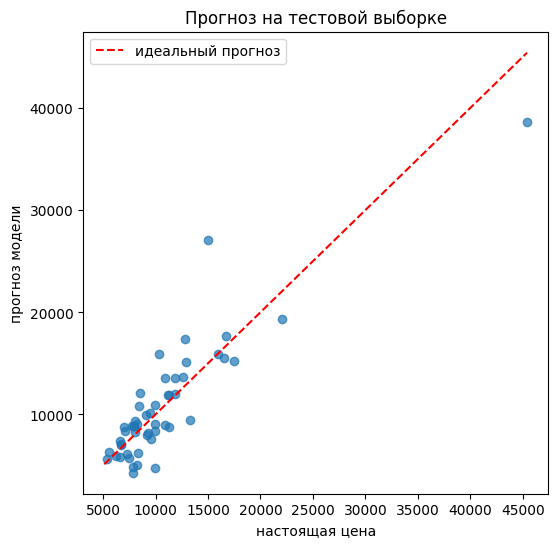

In [21]:
plt.figure(figsize=(6, 6))
plt.scatter(ytest, pred_test, alpha=0.7)
lims = [y.min(), y.max()]
plt.plot(lims, lims, 'r--', label='идеальный прогноз')
plt.xlabel('настоящая цена')
plt.ylabel('прогноз модели')
plt.title('Прогноз на тестовой выборке')
plt.legend()
plt.show()

### Посмотрим на веса модели

In [22]:
coefs = pd.Series(model.coef_, index=Xtrain.columns)
coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(10)

,0
engine-size,43123.491874
curb-weight,19339.840347
bore,-16005.113010
compression-ratio,-13310.546387
highway-mpg,12412.432126
num-of-cylinders_three,12305.043316
make_bmw,11195.288329
num-of-cylinders_four,10033.516815
make_audi,9450.851183
engine-type_rotor,8810.825057


In [23]:
print('Число признаков:', Xtrain.shape[1])
print('Ранг матрицы признаков:', np.linalg.matrix_rank(Xtrain))

Число признаков: 65
Ранг матрицы признаков: 60


Веса огромные и разных знаков, а ранг матрицы меньше числа признаков. Значит, некоторые признаки **линейно зависимы** — один выражается через другие. Например:

* все дизельные машины в датасете имеют систему впрыска `idi`, и только они: признаки `fuel-type_gas` и `fuel-system_idi` повторяют друг друга;
* роторный двигатель (`engine-type = rotor`) бывает только у машин с «двумя цилиндрами».

Модели всё равно, как поделить вес между одинаковыми столбцами, и веса «раскачиваются»: большой плюс у одного признака компенсируется большим минусом у другого. Интерпретировать такие веса нельзя. Лечится это отбором признаков или регуляризацией (о ней поговорим позже).

## 3. Новые признаки: бинаризация и полиномиальные признаки

Линейная модель умеет учитывать только линейные зависимости. Если цена зависит от признака нелинейно, можно помочь модели, добавив новые признаки. Сначала разберём идею на игрушечном примере.

### Игрушечный пример

Сгенерируем данные: от `X1` целевая переменная зависит линейно, а от `X2` — немонотонно (парабола).

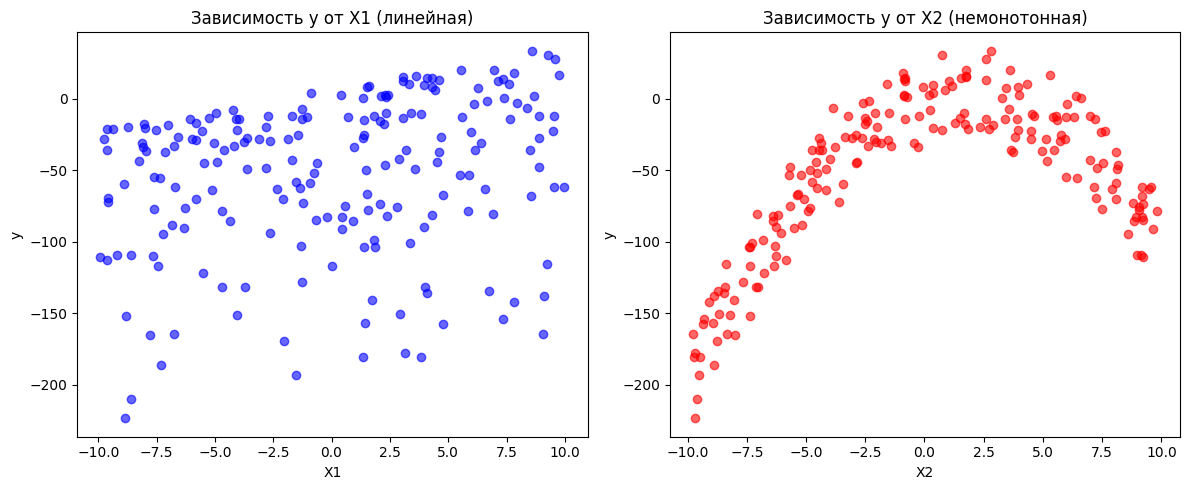

In [25]:
# Параметры
n_samples = 200       # Количество образцов
a = 3.0               # Коэффициент для линейной зависимости
b = 5.0               # Коэффициент для немонотонной зависимости
c = -1.5              # Коэффициент квадратичного члена
noise_std = 5.0       # Стандартное отклонение шума

# Генерация признаков
np.random.seed(0)
X1 = np.random.uniform(-10, 10, n_samples)  # Признак 1 (линейная зависимость с y)
X2 = np.random.uniform(-10, 10, n_samples)  # Признак 2 (немонотонная зависимость с y)

# Целевая переменная: линейная часть + нелинейная часть + шум
y_toy = a * X1 + b * X2 + c * X2 ** 2 + np.random.normal(0, noise_std, n_samples)

df_toy = pd.DataFrame({'X1': X1, 'X2': X2, 'y': y_toy})

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.scatter(df_toy['X1'], df_toy['y'], color='b', alpha=0.6)
plt.xlabel('X1'); plt.ylabel('y'); plt.title('Зависимость y от X1 (линейная)')
plt.subplot(1, 2, 2)
plt.scatter(df_toy['X2'], df_toy['y'], color='r', alpha=0.6)
plt.xlabel('X2'); plt.ylabel('y'); plt.title('Зависимость y от X2 (немонотонная)')
plt.tight_layout()
plt.show()

In [26]:
Xt_train, Xt_test, yt_train, yt_test = train_test_split(df_toy[['X1', 'X2']], df_toy['y'],
                                                        test_size=0.2, random_state=0)

toy_model = LinearRegression().fit(Xt_train, yt_train)
print(f"R² на тестовой выборке: {r2_score(yt_test, toy_model.predict(Xt_test)):.4f}")

R² на тестовой выборке: 0.2559


Нужно ли было масштабировать признаки? (Подсказка: для `LinearRegression` с аналитическим решением масштаб не влияет на прогнозы.)

#### Бинаризация

Разобьём `X2` на 4 интервала и сделаем из каждого интервала отдельный признак-индикатор. Тогда у каждого интервала будет свой вес, и модель сможет описать «сначала вверх, потом вниз».

**Важно:** границы интервалов считаем **только по обучающей выборке**, а к тестовой применяем те же границы. Если вызвать `pd.cut` на всех данных до разбиения, границы «увидят» тестовые объекты — это утечка данных.

In [27]:
# Границы 4 равных интервалов считаем по train; крайние границы расширяем до бесконечности,
# чтобы в тесте не было значений «вне интервалов»
_, bin_edges = pd.cut(Xt_train['X2'], bins=4, retbins=True)
bin_edges[0], bin_edges[-1] = -np.inf, np.inf


def add_x2_bins(X):
    X = X.copy()
    X['X2_bin'] = pd.cut(X['X2'], bins=bin_edges, labels=['bin1', 'bin2', 'bin3', 'bin4'])
    X = pd.get_dummies(X, columns=['X2_bin'], drop_first=True)
    return X.drop(columns='X2')


Xt_train_bins, Xt_test_bins = add_x2_bins(Xt_train), add_x2_bins(Xt_test)
Xt_train_bins.head()

,X1,X2_bin_bin2,X2_bin_bin3,X2_bin_bin4
134,1.399298,False,False,True
66,6.419865,True,False,False
26,-7.132934,False,True,False
113,-4.051261,False,False,False
168,4.599811,False,False,True


In [28]:
toy_bins = LinearRegression().fit(Xt_train_bins, yt_train)
print(f"R² на тестовой выборке: {r2_score(yt_test, toy_bins.predict(Xt_test_bins)):.4f}")
pd.Series(toy_bins.coef_, index=Xt_train_bins.columns)

R² на тестовой выборке: 0.7585


,0
X1,2.565414
X2_bin_bin2,91.572851
X2_bin_bin3,118.104094
X2_bin_bin4,72.150524


#### Полиномиальные признаки

Можно и проще: если подозреваем параболу, добавим квадраты признаков и их попарные произведения. `PolynomialFeatures(degree=2)` делает это автоматически: из (X1, X2) получается (X1, X2, X1², X1·X2, X2²). Модель остаётся линейной — по весам.

In [29]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

poly_pipeline = Pipeline([
    ('poly_features', PolynomialFeatures(degree=2, include_bias=False)),
    ('scaler', StandardScaler()),
    ('linear_regression', LinearRegression())
])
poly_pipeline.fit(Xt_train, yt_train)
print(f"R² на тестовой выборке: {r2_score(yt_test, poly_pipeline.predict(Xt_test)):.4f}")

feature_names = poly_pipeline.named_steps['poly_features'].get_feature_names_out(input_features=['X1', 'X2'])
pd.Series(poly_pipeline.named_steps['linear_regression'].coef_, index=feature_names).sort_values(key=abs, ascending=False)

R² на тестовой выборке: 0.9935


,0
X2^2,-42.810204
X2,29.125103
X1,17.627359
X1 X2,-0.368341
X1^2,-0.313914


Модель сама нашла, что важны `X2²` и `X2`, а `X1²` и `X1·X2` почти не нужны — ровно так, как мы генерировали данные.

### Теперь — на наших данных

Посмотрим, как цена зависит от нескольких признаков.

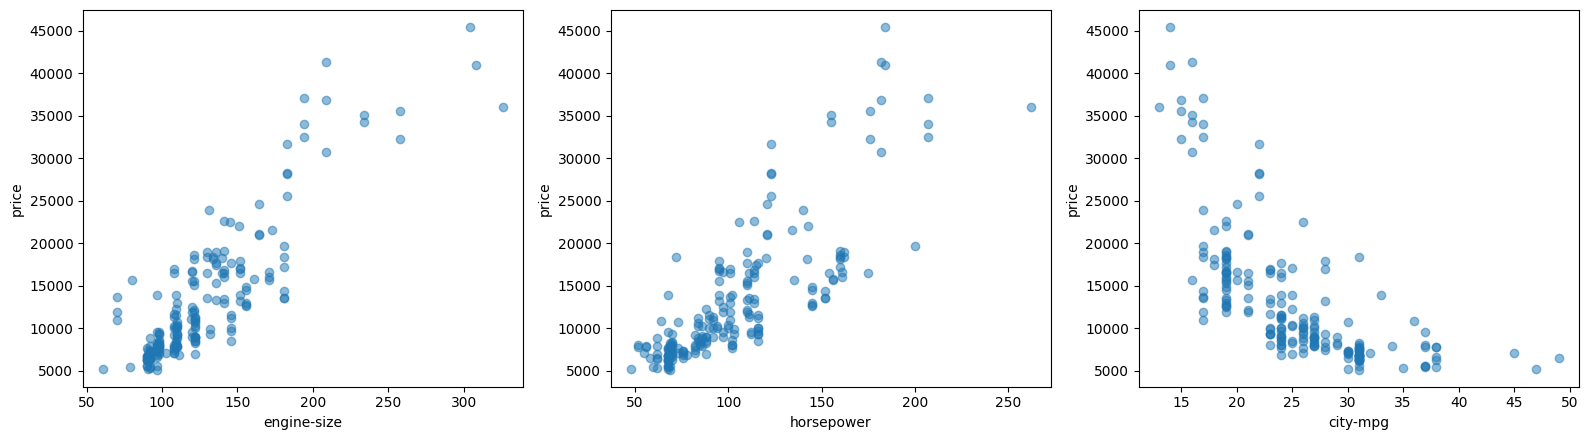

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ['engine-size', 'horsepower', 'city-mpg']):
    ax.scatter(X_no_mis[col], y, alpha=0.5)
    ax.set_xlabel(col)
    ax.set_ylabel('price')
plt.tight_layout()
plt.show()

* Цена растёт с объёмом двигателя и мощностью **быстрее, чем линейно** — облако точек загибается вверх. Добавим квадраты и произведение `engine-size` и `horsepower` (полиномиальные признаки).
* Зависимость от расхода `city-mpg` тоже нелинейная: у экономичных машин цена почти не меняется, у «прожорливых» резко растёт. Разобьём `city-mpg` на 4 интервала по квартилям **обучающей** выборки (бинаризация).

In [31]:
# Разбиваем те же объекты, что и в части 2: тот же размер выборки и тот же random_state
idx_train, idx_test = train_test_split(np.arange(len(X_no_mis)), test_size=0.25, random_state=123)

# Границы квартилей city-mpg — только по обучающей выборке
_, mpg_edges = pd.qcut(X_no_mis.loc[idx_train, 'city-mpg'], q=4, retbins=True)
mpg_edges[0], mpg_edges[-1] = -np.inf, np.inf


def add_features(df):
    df = df.copy()
    es, hp = df['engine-size'].astype('float64'), df['horsepower'].astype('float64')
    # полиномиальные признаки
    df['engine-size^2'] = es ** 2
    df['horsepower^2'] = hp ** 2
    df['engine-size*horsepower'] = es * hp
    # бинаризация
    df['city-mpg_bin'] = pd.cut(df['city-mpg'], bins=mpg_edges, labels=['q1', 'q2', 'q3', 'q4'])
    return df


X_fe = pd.get_dummies(add_features(X_no_mis), drop_first=True)
X_fe.columns = X_fe.columns.astype(str)
X_fe = X_fe.astype('float64')

Xtrain_fe, Xtest_fe = X_fe.iloc[idx_train], X_fe.iloc[idx_test]
ytrain_fe, ytest_fe = y.iloc[idx_train], y.iloc[idx_test]

# Масштабирование: на этот раз подбираем по train и применяем к test
scaler_fe = preprocessing.MinMaxScaler().fit(Xtrain_fe)
Xtrain_fe = pd.DataFrame(scaler_fe.transform(Xtrain_fe), columns=X_fe.columns)
Xtest_fe = pd.DataFrame(scaler_fe.transform(Xtest_fe), columns=X_fe.columns)

[c for c in X_fe.columns if '^2' in c or '*' in c or 'bin' in c]

['engine-size^2',
 'horsepower^2',
 'engine-size*horsepower',
 'city-mpg_bin_q2',
 'city-mpg_bin_q3',
 'city-mpg_bin_q4']

In [32]:
model_fe = LinearRegression().fit(Xtrain_fe, ytrain_fe)

results_part2 = pd.DataFrame({
    'линрег (test)': results_part1['линрег (test)'],
    '+ новые признаки (train)': regression_report(ytrain_fe, model_fe.predict(Xtrain_fe)),
    '+ новые признаки (test)': regression_report(ytest_fe, model_fe.predict(Xtest_fe)),
})
results_part2.round(3)

,линрег (test),+ новые признаки (train),+ новые признаки (test)
MAE,1973.963,881.149,1608.645
RMSE,2834.870,1188.690,2171.391
R2,0.772,0.980,0.866
MAPE,0.185,0.075,0.151
MaxError,12009.073,6099.907,6345.675


Новые признаки уменьшили ошибку на тесте: MAE и RMSE стали меньше, R² вырос. При этом разница между train и test осталась — переобучение никуда не делось, ведь признаков стало ещё больше.

Заметьте, сколько ручной работы понадобилось: следить за одинаковым разбиением, считать границы бинов по train, отдельно масштабировать train и test. Ошибиться здесь очень легко. Эту проблему решает пайплайн.

## 4. Пайплайн

**Пайплайн** (`Pipeline`) — цепочка шагов «предобработка → новые признаки → модель», которая ведёт себя как одна модель:

* `fit` на обучающей выборке подбирает **все** параметры — средние для пропусков, границы бинов, параметры масштабирования, веса модели — только по train;
* `predict` применяет те же преобразования к новым данным.

Поэтому утечка данных исключена, а весь процесс воспроизводится одной строкой. Пайплайн можно целиком передать в кросс-валидацию — этим займёмся на следующем занятии.

Разные группы столбцов обрабатываем по-разному с помощью `ColumnTransformer`:

In [33]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, KBinsDiscretizer
from sklearn import set_config

set_config(display='diagram')  # красивая схема пайплайна

# Разделяем ИСХОДНЫЕ данные — вся предобработка будет внутри пайплайна
X_train, X_test, y_train, y_test = train_test_split(X_raw, y, test_size=0.25, random_state=123)

num_cols = X_raw.columns[~cat_features_mask].tolist()
cat_cols = X_raw.columns[cat_features_mask].tolist()
poly_cols = ['engine-size', 'horsepower']
bin_cols = ['city-mpg']
other_num_cols = [c for c in num_cols if c not in poly_cols]

# Числовые признаки: пропуски → среднее, затем масштабирование
numeric = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler()),
])

# Полиномиальные признаки: x, x², попарные произведения
polynomial = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('scaler', StandardScaler()),
])

# Бинаризация: 4 интервала по квантилям обучающей выборки → OHE без первого столбца
binning = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('bins', KBinsDiscretizer(n_bins=4, encode='ordinal', strategy='quantile')),
    ('onehot', OneHotEncoder(drop='first')),
])

# Категориальные признаки: пропуски → 'NA', затем OHE
categorical = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='NA')),
    ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore')),
])

preprocessor = ColumnTransformer([
    ('num', numeric, other_num_cols),
    ('poly', polynomial, poly_cols),
    ('bins', binning, bin_cols),
    ('cat', categorical, cat_cols),
])

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression()),
])
pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['symboling',
                                                   'normalized-losses',
                                                   'wheel-base', 'length',
                                                   'width', 'height',
                                                   'curb-weight', 'bore',
                                                   'stroke',
                                                   'compression-ratio',
                                                   'peak-rpm', 'city-mpg',
                                                   'highway-mpg']),
                                                 ('poly',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImpu...
                                                                   OneHotEncoder(drop='first'))]),
                                                  ['city-mpg']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='NA',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(drop='first',
                                                                                 handle_unknown='ignore'))]),
                                                  ['make', 'fuel-type',
                                                   'aspiration', 'num-of-doors',
                                                   'body-style', 'drive-wheels',
                                                   'engine-location',
                                                   'engine-type',
                                                   'num-of-cylinders',
                                                   'fuel-system'])])),
                ('regressor', LinearRegression())])

`handle_unknown='ignore'`: если в тесте встретится категория, которой не было в train (например, редкая марка), все её индикаторы будут нулями — пайплайн не упадёт.

Обучение и прогноз — две строки:

In [34]:
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

results_pipeline = pd.DataFrame({
    'константа (test)': results_part1['константа (test)'],
    'линрег (test)': results_part1['линрег (test)'],
    '+ новые признаки (test)': results_part2['+ новые признаки (test)'],
    'пайплайн (train)': regression_report(y_train, pipeline.predict(X_train)),
    'пайплайн (test)': regression_report(y_test, y_pred),
})
results_pipeline.round(3)

,константа (test),линрег (test),+ новые признаки (test),пайплайн (train),пайплайн (test)
MAE,5315.482,1973.963,1608.645,911.594,1680.104
RMSE,6806.426,2834.870,2171.391,1218.663,2358.962
R2,-0.314,0.772,0.866,0.979,0.842
MAPE,0.583,0.185,0.151,0.078,0.158
MaxError,31349.120,12009.073,6345.675,5865.813,7754.069


Пайплайн даёт качество того же порядка, что и ручная версия с новыми признаками (небольшие отличия — из-за другого масштабирования и кодирования), но без ручной работы и без утечки данных.

Названия признаков после всех преобразований и веса модели тоже можно достать из пайплайна:

In [35]:
feature_names = pipeline.named_steps['preprocessor'].get_feature_names_out()
pipe_coefs = pd.Series(pipeline.named_steps['regressor'].coef_, index=feature_names)
pipe_coefs[[n for n in feature_names if n.startswith(('poly__', 'bins__'))]]

,0
poly__engine-size,4922.728727
poly__horsepower,-5271.885939
poly__engine-size^2,-2445.561083
poly__engine-size horsepower,5585.755420
poly__horsepower^2,1138.251069
bins__city-mpg_1.0,-1718.885899
bins__city-mpg_2.0,-542.326096
bins__city-mpg_3.0,25.650666


## Итоги

* Предобработка: пропуски, типы данных, OHE с `drop_first`, масштабирование.
* Линейная регрессия без регуляризации на 60+ признаках переобучается, а её веса из-за линейно зависимых признаков нельзя интерпретировать.
* Метрики смотрим вместе: MAE и RMSE — в долларах, R² — сравнение с константой, MAPE — в процентах, MaxError — худший случай.
* Бинаризация и полиномиальные признаки помогают линейной модели описать нелинейные зависимости.
* Пайплайн собирает предобработку, новые признаки и модель в один объект: никаких утечек и ручной синхронизации train/test.

На следующем занятии: разные функции потерь и сравнение пайплайнов на кросс-валидации.